# Chapter 09 답안. 회귀 분석으로 숫자 예측하기

## 제출 정보

- 이름: 송누리
- GitHub ID: HauserNR
- 작성일: 2026-11-12
- 최종 Notebook URL: [chapter09/chapter09.ipynb](https://github.com/HauserNR/llm-data-analysis-study/blob/main/chapter09/chapter09.ipynb)

## 1. 예측 문제 정의

- Target: `order_total` (원)
- 예측 단위: 주문 1건
- 예측 시점: 주문 헤더·선택 결제수단·고객 특성은 분석 시스템에 기록됐지만 주문 상세 수량·단가·금액은 아직 제공되지 않은 시점
- 예측 시점에 알 수 있는 정보: 주문 월·요일, 고객 나이·성별·도시, 결제수단 (당시 제공된다고 가정)
- 예측 시점에 알 수 없는 정보: 상세 수량·단가·합계, 상품 수·총수량·평균단가, 최종 주문 상태

### 나의 해석과 판단

메타데이터만 먼저 제공되는 상황의 금액 추정 가능성을 확인하기 위해 이 시점을 정했다. 실제 기록 시각과 고객 속성 이력이 없어 이 가정은 검증하지 못했다. 실제 서비스에서는 시점 가용성을 먼저 확인해야 한다. 상세가 이미 제공된다면 금액은 합산으로 계산한다. Target은 취소·환불을 포함한 주문 상세의 명목 합계이며 순매출이 아니다.

공통 프로젝트 `data/raw` 4개를 준비하고 PK/FK·금액·날짜·행 손실을 검사한 뒤 `data/processed/*_clean.csv`를 생성한다. 모델 Feature의 결측 대체는 Pipeline 안에서만 수행한다.


In [1]:
from pathlib import Path
import sys
import pandas as pd

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name in ('notebooks', 'chapter09') else CURRENT_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'

from src.regression import (
    FEATURE_COLUMNS,
    FORBIDDEN_FEATURES,
    TARGET_COLUMN,
    build_feature_audit,
    build_leakage_checklist,
    build_regression_dataset,
    build_regression_validation,
    build_split_summary,
    create_prediction_result,
    cross_validate_regression_models,
    load_regression_source_data,
    make_regression_models,
    run_regression_analysis,
    save_regression_outputs,
    select_diagnostic_model,
    split_model_data_by_time,
    train_and_evaluate_models,
    validate_feature_columns,
)

print('PROJECT_ROOT:', PROJECT_ROOT)
print('PROCESSED_DIR:', PROCESSED_DIR)
from scripts.prepare_ch09_data import prepare_ch09_data
preparation = prepare_ch09_data()
display(preparation['relationship_checks'])
display(pd.read_csv(REPORT_DIR / 'ch09_source_checks.csv'))


PROJECT_ROOT: /Users/kjj/MyLLMGit/llm-data-analysis-study
PROCESSED_DIR: /Users/kjj/MyLLMGit/llm-data-analysis-study/data/processed


,check,invalid_count
0,orders.customer_id exists in customers.custome...,0
1,order_items.order_id exists in orders.order_id,0
2,order_items.product_id exists in products.prod...,0


,check,status
0,customers_pk,PASS
1,products_pk,PASS
2,orders_pk,PASS
3,order_items_pk,PASS
4,orders_customer_id_fk,PASS
5,order_items_order_id_fk,PASS
6,order_items_product_id_fk,PASS
7,every_order_has_detail,PASS
8,amounts_finite_positive,PASS
9,dates_valid,PASS


## 2. Feature Leakage Audit

아래 표의 `column`은 feature, `available_at_prediction`은 예측 시점 사용 가능, `target_ingredient`는 Target 계산 재료·대리 집계, `post_event_or_id`는 사후 정보/ID, `selected`는 최종 사용, `reason`은 판단 이유다. True/False로 모든 허용·금지 열을 점검한다.

- 금지 feature overlap 개수: **0**
- 가장 위험하다고 판단한 feature: **order_total**
- 이유: 예측할 정답 자체이므로 입력에 포함하면 정답을 모델에 제공하는 직접 누수다. `line_total`·수량·단가와 상세 집계도 Target 구성 또는 대리 정보여서 제외한다. `order_status`는 사후 정보이며 ID는 식별·암기 위험이 있어 제외한다. 주문 ID와 고객 ID가 시점상 알려져 있어도 Feature로 사용하지 않는다.


In [2]:
print('Target:', TARGET_COLUMN)
print('Allowed features:', FEATURE_COLUMNS)
print('Forbidden features:', sorted(FORBIDDEN_FEATURES))
validate_feature_columns()
print('Feature leakage gate: PASS')
feature_audit = build_feature_audit()
display(feature_audit)
print('forbidden feature overlap:', len(set(FEATURE_COLUMNS) & FORBIDDEN_FEATURES))

Target: order_total
Allowed features: ['order_month', 'order_dayofweek', 'age', 'payment_method', 'gender', 'city']
Forbidden features: ['avg_unit_price', 'customer_id', 'item_count', 'line_total', 'order_id', 'order_status', 'order_total', 'product_id', 'quantity', 'total_quantity', 'unit_price']
Feature leakage gate: PASS


,column,selected,role,reason,available_at_prediction,target_ingredient,post_event_or_id
0,order_month,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정,True,False,False
1,order_dayofweek,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정,True,False,False
2,age,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정,True,False,False
3,payment_method,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정,True,False,False
4,gender,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정,True,False,False
5,city,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정,True,False,False
6,avg_unit_price,False,forbidden,주문 상세에서 만든 목표 대리 변수,False,True,False
7,customer_id,False,forbidden,고객 식별자,True,False,True
8,item_count,False,forbidden,주문 상세가 확인된 뒤 계산되는 사후 집계,False,True,False
9,line_total,False,forbidden,목표값을 구성하는 주문 상세 금액,False,True,False


forbidden feature overlap: 0


![Leakage 점검 결과표](images/step02_leakage.png)

## 3. Target 생성과 관계 검증

### 계산 기준

```text
line_total = quantity × unit_price
order_total = 같은 order_id의 line_total 합계
```

- line_total 검증 결과: 계산값과 전처리 데이터의 `line_total` 불일치 **0건**
- orders ↔ target 관계 검증 결과: `one_to_one` PASS, 미매칭 주문·상세 없음
- orders → customers 관계 검증 결과: `many_to_one` PASS, 미매칭 고객 없음

### 나의 해석과 판단

관계 검사 없이 병합하면 중복 키로 행·금액이 늘거나 FK 미매칭으로 주문이 사라질 수 있다. 따라서 실패 시 예외를 발생시켜 모델링을 중단한다. 원본에는 독립적인 합계 정답 열이 없어 외부 거래 원장과 대조한 것은 아니다.


In [3]:
data = load_regression_source_data(PROCESSED_DIR)
for name, frame in data.items():
    print(name, frame.shape)

customers (150, 6)
orders (300, 7)
order_items (764, 6)


In [4]:
model_data = build_regression_dataset(
    customers=data['customers'],
    orders=data['orders'],
    order_items=data['order_items'],
)
print('line_total 불일치:', int((data['order_items'].line_total - data['order_items'].quantity * data['order_items'].unit_price).abs().gt(1e-6).sum()))
print('상세 합계와 주문 Target 합계:', data['order_items'].line_total.sum(), model_data.order_total.sum())
assert abs(data['order_items'].line_total.sum() - model_data.order_total.sum()) < 1e-6
print('관계 검증: orders ↔ target one_to_one, orders → customers many_to_one PASS')
print('Model rows:', len(model_data))

line_total 불일치: 0
상세 합계와 주문 Target 합계: 255610000 255610000
관계 검증: orders ↔ target one_to_one, orders → customers many_to_one PASS
Model rows: 300


## 4. Train / Final Test 분할

- Train 시작일: 2025-09-15
- Train 종료일: 2026-06-25
- Train 행 수: 237
- Final Test 시작일: 2026-06-30
- Final Test 종료일: 2026-09-15
- Final Test 행 수: 63
- 같은 달력 날짜 중복 여부: **없음**

### 분할 판단

과거 주문에서 학습해 이후 주문을 예측하는 상황을 평가하기 위해 시간순으로 나눴다. 고유 주문일의 마지막 약 20%를 Test로 두므로 행 수 비율은 Train 79%, Test 21%다. `train max date < final test min date`를 assert로 검사한다. Test를 후보 선택에 사용하지 않는다.


In [5]:
train_data, test_data = split_model_data_by_time(model_data, test_size=0.2)
split_summary = build_split_summary(train_data, test_data)
display(split_summary)
assert train_data['order_date'].max().normalize() < test_data['order_date'].min().normalize()
print('Chronological split gate: PASS')

,split,rows,ratio_pct,start_date,end_date
0,train,237,79.0,2025-09-15,2026-06-25
1,test,63,21.0,2026-06-30,2026-09-15


Chronological split gate: PASS


In [6]:
X_train = train_data[FEATURE_COLUMNS].copy()
X_test = test_data[FEATURE_COLUMNS].copy()
y_train = train_data[TARGET_COLUMN].copy()
y_test = test_data[TARGET_COLUMN].copy()
print('Train:', X_train.shape, 'Final Test:', X_test.shape)

Train: (237, 6) Final Test: (63, 6)


![시간 분할 결과표](images/step04_split.png)

## 5. Train TimeSeriesSplit 후보 비교

각 Train fold에서 숫자형 median imputation → StandardScaler, 범주형 most_frequent imputation → OneHotEncoder(handle_unknown="ignore")를 Pipeline 안에서 적합한다. 후보는 평균 Baseline, 선형회귀, Random Forest이며 Train 내부 TimeSeriesSplit 5개 fold만으로 비교한다.

| 모델 | CV MAE 평균 | CV MAE 표준편차 | CV R² 평균 | 비고 |
|---|---:|---:|---:|---|
| Baseline Mean | 410,874.65 | 56,733.91 | -0.0164 | 비교 기준 |
| Random Forest | 435,531.63 | 65,609.85 | -0.1245 | 비베이스라인 후보 |
| Linear Regression | 531,449.81 | 224,650.65 | -0.7380 | 비베이스라인 후보 |

### Train CV로 선택한 비베이스라인 모델

- Selected Model: **Random Forest**
- 선택 기준: Baseline을 제외한 두 후보 중 `cv_MAE_mean` 최소 (동률이면 모델명 순)
- Final Test 결과를 보기 전에 선택했는가: **예 — 현재 제출본에서는 Train CV로 선택을 고정한 뒤 Final Test를 계산한다.** 과거 Test 일부 열람 이력에 따른 독립성 한계는 10번에 명시했다.

### 나의 해석과 판단

Random Forest는 선형회귀보다 CV MAE 평균과 표준편차가 작다. 그러나 Baseline보다 CV MAE가 크고 CV R² 평균도 음수여서 추가 가치를 입증한 것은 아니다. 평균만 보면 시기별 변동을 놓칠 수 있으므로 표준편차도 함께 본다. 특히 선형회귀의 큰 표준편차는 작은 초기 Train 구간에서 불안정할 수 있음을 시사한다.


In [7]:
models = make_regression_models(random_state=42)
print(list(models))

['Baseline Mean', 'Linear Regression', 'Random Forest']


In [8]:
cv_summary = cross_validate_regression_models(
    models=models,
    X_train=X_train,
    y_train=y_train,
)
display(cv_summary)

,model,n_splits,cv_MAE_mean,cv_MAE_std,cv_R2_mean
0,Baseline Mean,5,410874.650840,56733.910438,-0.016351
1,Random Forest,5,435531.631057,65609.845361,-0.124451
2,Linear Regression,5,531449.805561,224650.649047,-0.738022


In [9]:
selected_model_name = select_diagnostic_model(cv_summary)
print('Frozen selected model:', selected_model_name)

Frozen selected model: Random Forest


## 6. Final Test: Baseline vs Frozen Model

선택 고정 후 Baseline Mean과 Frozen Random Forest 두 모델만 평가한다.

| 모델 | selection role | Train MAE | Test MAE | Test RMSE | Test R² | Baseline 대비 MAE 개선율 |
|---|---|---:|---:|---:|---:|---:|
| Baseline Mean | baseline | 411,601.31 | 457,770.01 | 576,665.89 | -0.0004 | 0.00% |
| Frozen Selected Model (Random Forest) | selected_by_train_cv | 323,954.50 | 454,459.65 | 589,208.94 | -0.0444 | 0.72% |

### 결과 관찰

Random Forest의 Test MAE는 약 454,460원으로 Baseline보다 0.72% 낮다. RMSE는 약 589,209원으로 Baseline의 576,666원보다 높다. Train MAE 약 323,954원보다 Test MAE가 커 일반화 격차가 있다.

### 나의 해석과 판단

- Frozen Model이 baseline보다 실제로 개선되었는가? **MAE는 0.72% 개선됐지만 RMSE는 악화됐다.**
- MAE와 RMSE 차이에서 무엇을 볼 수 있는가? RMSE가 MAE보다 커 일부 큰 오차의 영향을 받는다. 고액 주문의 오차까지 개선됐다고 말할 수 없다.
- R²는 어떻게 해석할 수 있는가? **−0.0444**로, Test 정답 평균을 사후에 사용하는 기준보다 설명력이 낮다. 음수라는 사실만으로 코드 오류를 뜻하지는 않는다.

### 업무·분석적 의미

주문 1건당 평균 절대 오차가 약 45만원이다. 단일 기간 63건에서 0.72% 개선된 결과만으로 주문별 가격·예산·물량 계획에 적용하기 어렵다. 불확실성 구간이나 별도 미래 기간 검증은 수행하지 않았다.


In [10]:
model_comparison, predictions = train_and_evaluate_models(
    models=models,
    selected_model_name=selected_model_name,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
)
display(model_comparison)

,model,selection_role,train_MAE,test_MAE,test_RMSE,test_R2,MAE_improvement_vs_baseline_pct
0,Baseline Mean,baseline,411601.310331,457770.008707,576665.886056,-0.000369,0.00
1,Random Forest,selected_by_train_cv,323954.495771,454459.654727,589208.941683,-0.044360,0.72


![최종 회귀 평가 결과표](images/step06_final_metrics.png)

## 7. 대표 오차 사례

`residual = actual − predicted`로 정의한다. 공개 표에는 주문 ID를 표시하지 않고 절대 오차 순서로 사례를 구분한다.


In [11]:
prediction_result = create_prediction_result(test_data, y_test, predictions[selected_model_name], selected_model_name)
from src.regression import public_prediction_result
# 공개 Notebook에는 원본 식별자를 제외한다.
display(public_prediction_result(prediction_result).head(3).round({'predicted_order_total':2,'residual':2,'abs_error':2}))
print('order_id 포함 원본은 로컬 internal 파일에만 저장한다.')

,order_date,actual_order_total,predicted_order_total,residual,abs_error,model
0,2026-07-08,2821000,757408.26,2063591.74,2063591.74,Random Forest
1,2026-07-14,2118000,813018.92,1304981.08,1304981.08,Random Forest
2,2026-07-21,2053000,833252.71,1219747.29,1219747.29,Random Forest


order_id 포함 원본은 로컬 internal 파일에만 저장한다.


### 사례 1

- 실제값: 2,821,000.00원
- 예측값: 757,408.26원
- residual: 2,063,591.74원
- absolute error: 2,063,591.74원
- 관찰: 고액 주문을 과소예측했다.
- 가능한 이유 후보: 품목 구성·수량·단가의 조합으로 큰 금액이 만들어졌을 가능성. 상세를 확인하기 전의 가설이다.
- 추가 확인: 해당 주문의 상세 품목·수량·단가와 유사한 사전 특성을 가진 주문의 금액 분포
- 현재 모델의 한계: 현재 메타데이터만으로 장바구니 규모를 구별하기 어렵다. 상세는 사후 진단에만 사용하고 Feature로 추가하지 않는다.


### 사례 2

- 실제값: 2,118,000.00원
- 예측값: 813,018.92원
- residual: 1,304,981.08원
- absolute error: 1,304,981.08원
- 관찰: 고액 주문을 과소예측했다.
- 가능한 이유 후보: 품목 구성·수량·단가의 조합으로 큰 금액이 만들어졌을 가능성. 상세를 확인하기 전의 가설이다.
- 추가 확인: 해당 주문의 상세 품목·수량·단가와 유사한 사전 특성을 가진 주문의 금액 분포
- 현재 모델의 한계: 현재 메타데이터만으로 장바구니 규모를 구별하기 어렵다. 상세는 사후 진단에만 사용하고 Feature로 추가하지 않는다.


### 사례 3

- 실제값: 2,053,000.00원
- 예측값: 833,252.71원
- residual: 1,219,747.29원
- absolute error: 1,219,747.29원
- 관찰: 고액 주문을 과소예측했다.
- 가능한 이유 후보: 품목 구성·수량·단가의 조합으로 큰 금액이 만들어졌을 가능성. 상세를 확인하기 전의 가설이다.
- 추가 확인: 해당 주문의 상세 품목·수량·단가와 유사한 사전 특성을 가진 주문의 금액 분포
- 현재 모델의 한계: 현재 메타데이터만으로 장바구니 규모를 구별하기 어렵다. 상세는 사후 진단에만 사용하고 Feature로 추가하지 않는다.


## 8. Validation Evidence

`reports/ch09_regression_validation.csv` 기준이다.

| check | value | status |
|---|---|---|
| forbidden_feature_overlap | 0 | PASS |
| strict_train_before_test | True | PASS |
| selected_model_exists_in_train_cv | True | PASS |
| final_test_contains_baseline | True | PASS |
| final_test_contains_frozen_selected_model | True | PASS |
| test_rows_for_r2 | 63 | PASS |

### FAIL 항목

- 없음 / 있음: **없음**
- 있다면 원인과 수정 내용: 해당 없음. 자동 Validation의 모든 status가 PASS이며 실패 시 코드가 예외를 발생시킨다. 이 자동 검사는 과거 결과 열람 이력이나 실제 시스템의 정보 제공 시각을 검증하지 못한다. 사람 검토 체크리스트의 PASS도 현재 제출본의 실행 절차와 명시한 교육용 시점 가정에 한정되며, 완전히 독립적인 미래 검증이나 운영 시각 확인을 뜻하지 않는다.


In [12]:
validation = build_regression_validation(
    train_data=train_data,
    test_data=test_data,
    cv_summary=cv_summary,
    selected_model_name=selected_model_name,
    model_comparison=model_comparison,
)
display(validation)
assert validation['status'].eq('PASS').all()

,check,value,status
0,forbidden_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_selected_model,True,PASS
5,test_rows_for_r2,63,PASS


## 9. Evidence와 공개 범위

### 생성된 Evidence

- [x] `ch09_regression_split_summary.csv`
- [x] `ch09_regression_feature_audit.csv`
- [x] `ch09_regression_cv_summary.csv`
- [x] `ch09_regression_model_comparison.csv`
- [x] `ch09_regression_validation.csv`
- [x] `ch09_regression_checklist.csv`

### Internal 파일

- [x] `ch09_regression_model_data_internal.csv` — 로컬 생성, GitHub 게시 제외
- [x] `ch09_regression_predictions_internal.csv` — 로컬 생성, GitHub 게시 제외

### 공개 결과

- [x] `ch09_regression_report.md`
- [x] `ch09_actual_vs_predicted.png`
- [x] `ch09_residual_histogram.png`

CSV·보고서는 `reports/`, 두 그래프는 `reports/figures/`에 생성한다.

### 공개 범위 판단

주문 ID는 원본 고객·거래와 다시 연결하는 키가 될 수 있으므로 ID 포함 예측 결과는 Internal로 구분하고 `.gitignore`로 게시에서 제외한다. 공개 Notebook·보고서·그림에는 원본 주문 ID를 표시하지 않는다. 실습 표본은 가상이지만 실제 데이터의 공개 범위 원칙을 적용했다.


In [13]:
checklist = build_leakage_checklist()
output_paths = save_regression_outputs(
    model_data=model_data,
    split_summary=split_summary,
    feature_audit=feature_audit,
    cv_summary=cv_summary,
    selected_model_name=selected_model_name,
    model_comparison=model_comparison,
    prediction_result=prediction_result,
    validation=validation,
    checklist=checklist,
    report_dir=REPORT_DIR,
)
for name, path in output_paths.items():
    print(name, '->', path)
# 답안 템플릿의 이미지 경로에 실제 결과표를 저장한다 (화면 캡처가 아닌 결과표 시각화).
import matplotlib.pyplot as plt
image_dir = PROJECT_ROOT / 'chapter09' / 'images'
image_dir.mkdir(exist_ok=True)
def save_evidence_table(frame, name, title, width):
    fig, ax = plt.subplots(figsize=(width, max(2.5, 0.38 * (len(frame) + 2))))
    ax.axis('off')
    ax.set_title(title, pad=15)
    table = ax.table(cellText=frame.astype(str).values, colLabels=frame.columns, loc='center', cellLoc='left')
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.5)
    fig.savefig(image_dir / name, dpi=150, bbox_inches='tight')
    plt.close(fig)
save_evidence_table(feature_audit[['column','available_at_prediction','target_ingredient','post_event_or_id','selected']], 'step02_leakage.png', 'Feature Leakage Audit', 16)
save_evidence_table(split_summary, 'step04_split.png', 'Chronological Train / Final Test Split', 12)
save_evidence_table(model_comparison.round(3), 'step06_final_metrics.png', 'Final Test: Baseline vs Frozen Random Forest', 19)


model_data_internal -> /Users/kjj/MyLLMGit/llm-data-analysis-study/reports/ch09_regression_model_data_internal.csv
split_summary -> /Users/kjj/MyLLMGit/llm-data-analysis-study/reports/ch09_regression_split_summary.csv
feature_audit -> /Users/kjj/MyLLMGit/llm-data-analysis-study/reports/ch09_regression_feature_audit.csv
cv_summary -> /Users/kjj/MyLLMGit/llm-data-analysis-study/reports/ch09_regression_cv_summary.csv
model_comparison -> /Users/kjj/MyLLMGit/llm-data-analysis-study/reports/ch09_regression_model_comparison.csv
predictions_internal -> /Users/kjj/MyLLMGit/llm-data-analysis-study/reports/ch09_regression_predictions_internal.csv
validation -> /Users/kjj/MyLLMGit/llm-data-analysis-study/reports/ch09_regression_validation.csv
checklist -> /Users/kjj/MyLLMGit/llm-data-analysis-study/reports/ch09_regression_checklist.csv
report -> /Users/kjj/MyLLMGit/llm-data-analysis-study/reports/ch09_regression_report.md
actual_vs_predicted_figure -> /Users/kjj/MyLLMGit/llm-data-analysis-study/re

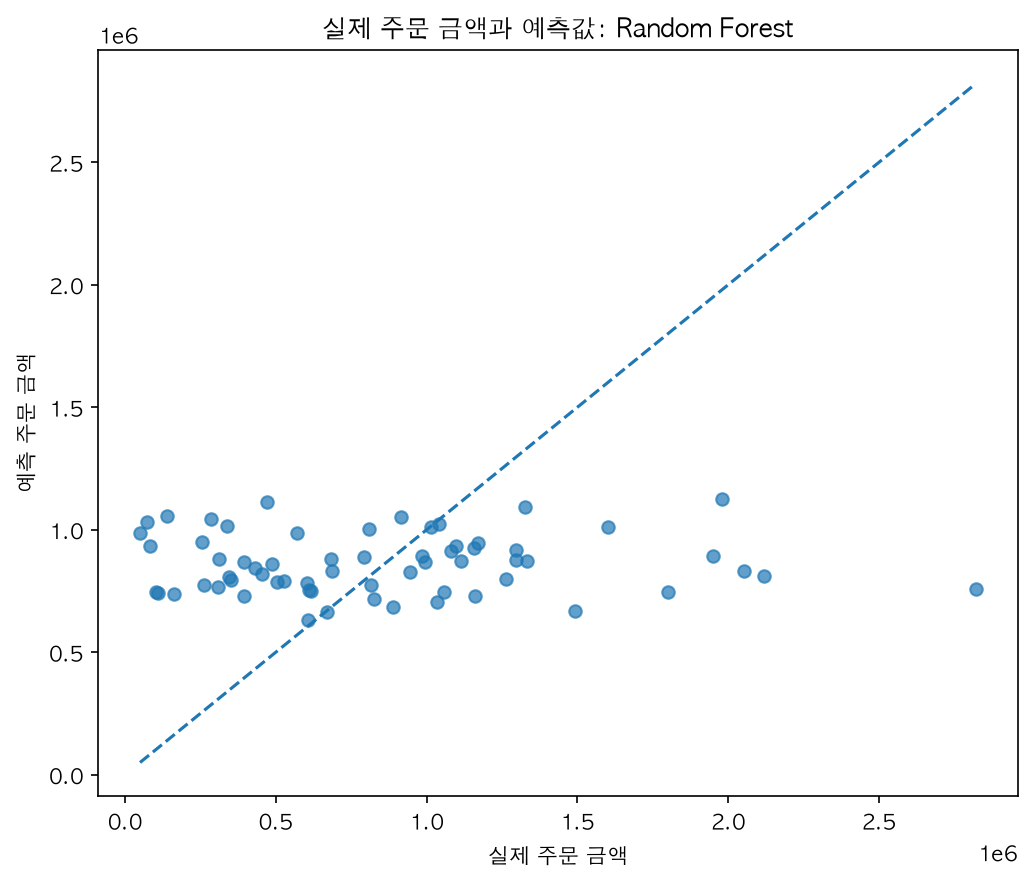

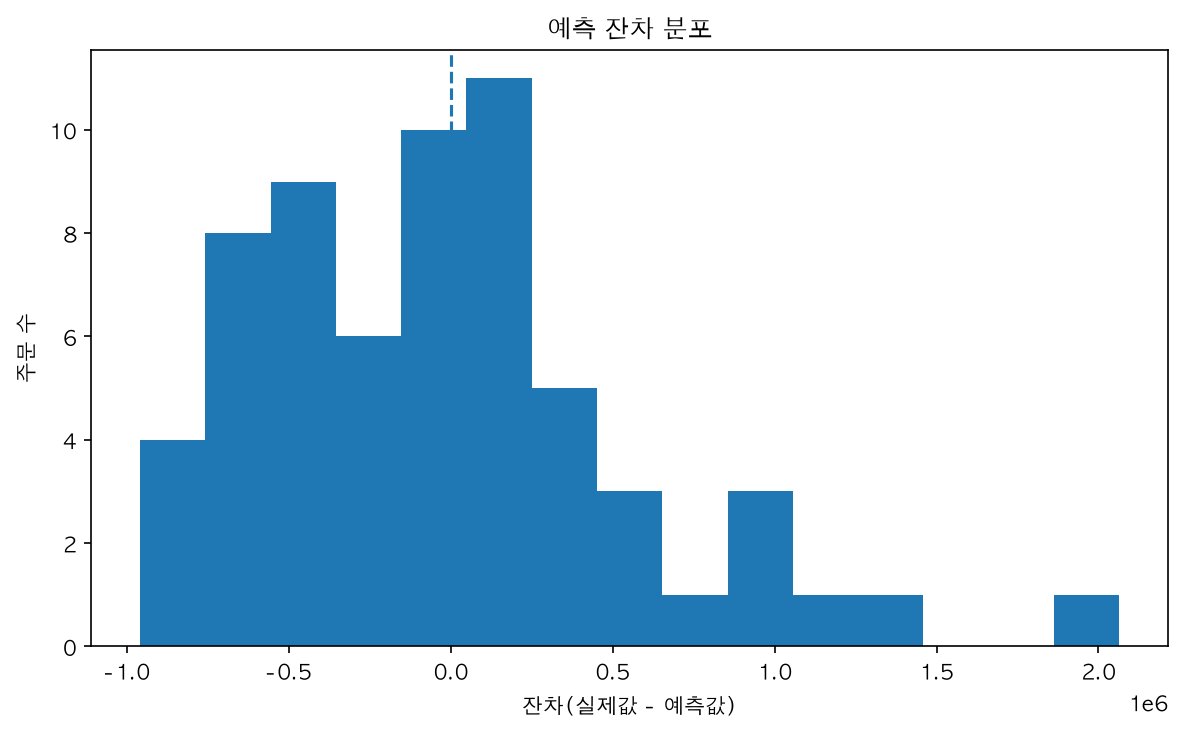

In [14]:
from IPython.display import Image, display
for key in ['actual_vs_predicted_figure', 'residual_figure']:
    display(Image(filename=str(output_paths[key])))

### 그래프 관찰·해석·업무 의미·한계

실제값–예측값 그림에서 고액 주문이 대각선에서 멀리 떨어져 과소예측된다. 잔차 분포에도 큰 양의 잔차가 있다. 업무적으로 큰 주문의 금액 추정에 주의가 필요하며, 두 그림만으로 원인을 확정할 수 없다.

## 10. 최종 사용 판단

- [ ] 현재 수준에서 참고용 사용 가능
- [ ] 추가 검증 후 사용 가능
- [x] 현재 데이터로는 사용 보류

### 판단 근거

1. Train CV에서 Random Forest는 선형회귀보다 안정적이지만 Baseline을 이기지 못했다.
2. Final Test MAE 개선율은 약 0.72%로 작다. RMSE는 악화됐고 R²는 음수이며, 대표 고액 주문에서 약 122만~206만원의 오차가 관찰됐다.
3. 누수 금지 열 제외·Train Pipeline·시간순 분할·Validation을 통과했지만 예측 유용성을 보장하지는 않는다.

### 업무적 위험

고액 주문의 과소예측이 예산·물량 계획을 왜곡할 수 있다. 평균 오차가 약 45만원인 상태에서 주문별 자동 의사결정에 바로 쓰기 어렵다.

### 현재 데이터의 한계

300건의 가상 표본이며 고객 속성의 주문 당시 이력, 상세 제공 시각, 할인·배송비·세금 정보가 없다. 고객 나이와 결제수단이 그 시점에 제공된다는 가정도 로그로 검증해야 한다.

이전 버전은 Baseline을 선택 후보에 포함하고 마지막 두 달을 평가했다. 이를 공식 비베이스라인 선택·날짜 분할로 정정했다. 이전 버전에서 현재 Test 일부를 이미 열람했으므로 완전히 독립적인 미래 평가라고 주장하지 않는다. 현재 코드의 모델 선택에는 Train CV만 사용했지만 실제 사용 판단에는 새로 수집한 미래 기간 검증이 필요하다.

### 다음 개선 우선순위

1. 기록 시각과 당시 고객 속성을 검증하고 예측 시점에 존재하는 추가 신호를 수집한다.
2. 새 미래 기간과 더 많은 주문으로 성능과 불확실성을 검증한다.
3. Train에서만 모델·설정을 검토하고 별도 미래 Test를 한 번 평가해 업무 허용 오차와 비교한다.

### LLM 활용 및 검증

LLM을 코드 작성·누수 Feature 검토·지표 해석에 사용했다. 상세 집계 Feature는 시점상 금지하여 제외했고, 모델은 실제 Train CV로 비교했다. Random Forest의 비베이스라인 CV 우위와 Test의 소폭 MAE 개선을 실행 결과로 확인했으며, RMSE 악화·음수 R²·평가 한계를 함께 판단했다.

## 11. 전체 재실행 확인

실행 명령:

```bash
python scripts/prepare_ch09_data.py
python scripts/run_regression_analysis.py
```

- 실행 성공 여부: **성공**
- Train CV Selected Model: **Random Forest**
- Final Validation 전체 PASS 여부: **PASS**
- Notebook 결과와 스크립트 결과의 일관성: 아래 새 실행 결과와 `assert_frame_equal`로 CV 및 최종 지표의 일치를 확인한다.

같은 데이터의 재실행은 재현성 확인이며 새로운 미래 검증이 아니다.


In [15]:
result = run_regression_analysis(
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    test_size=0.2,
    random_state=42,
)
print('Selected by Train CV:', result['selected_model_name'])
display(result['validation'])
pd.testing.assert_frame_equal(cv_summary, result['cv_summary'])
pd.testing.assert_frame_equal(model_comparison, result['model_comparison'])
print('Notebook ↔ 새 실행 CV/Final Test 결과 일치: PASS')


Selected by Train CV: Random Forest


,check,value,status
0,forbidden_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_selected_model,True,PASS
5,test_rows_for_r2,63,PASS


Notebook ↔ 새 실행 CV/Final Test 결과 일치: PASS


## 최종 체크

- [x] Target과 예측 시점을 정의했습니다.
- [x] Leakage Audit을 수행했습니다.
- [x] Target 계산과 관계 검증을 확인했습니다.
- [x] Train과 Final Test가 시간 순서로 엄격히 분리되었습니다.
- [x] 전처리가 Pipeline 내부에서 학습됩니다.
- [x] Train TimeSeriesSplit으로 후보를 비교했습니다.
- [x] Final Test 전에 Selected Model을 고정했습니다.
- [x] Final Test에서는 Baseline과 Frozen Model만 비교했습니다.
- [x] MAE, RMSE, R²를 함께 해석했습니다.
- [x] 대표 오차 사례를 관찰과 가설로 구분했습니다.
- [x] Validation Evidence가 모두 PASS입니다.
- [x] Internal 결과와 공개 결과를 구분했습니다.
- [x] 낮은 성능도 숨기지 않았습니다.
- [x] 전체 스크립트를 재실행했습니다.
- [x] 최종 Notebook URL을 제출합니다.

체크리스트는 현재 제출본의 실행 절차 기준이다. 2026-11-12에 사용자로부터 최종 Notebook URL의 LMS 제출 완료를 확인했다. 모델 선택 순서는 현재 코드 기준이며 이전 Test 열람 이력은 10번의 평가 한계에 명시했다.
